# Лабораторна 1. Основні бібліотеки. Лінійні моделі навчання.

В цій лабораторній роботі студенти:
- ознайомлюються з сервісом Colab;
- ознайомлюються з базовими бібліотеками для машинного навчання;
- тренують неглибокі лінійні моделі машинного навчання на базі простих регресій: лінійна, логістична, поліноміальна.

## 0. Налаштування середовища

### 0.0. Імпортуємо залежності

In [67]:
import sys
import os
import random
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt

### 0.1. Перевіряємо чи ми точно в Colab

In [68]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

assert IN_COLAB, f"Ця лаба має вокинуватися в Google Colab (https://colab.research.google.com/)"

Running in Colab: True


### 0.2. Фіксуємо всі джерела випадковості.
На GPU повна детермінованість трохи сповільнює тренування
(`cudnn.deterministic = True` вимикає частину швидких алгоритмів) —
тут це не критично, адже дані й модель дрібні.

In [69]:
SEED = 42

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

**Вправа 1.** Скористайся вбудованим модулем `random`. Спробуй `random.randint(1, 100)` і `random.shuffle()` на списку — випадковість буває не лише в числі, а й у перестановці. Згенеруй обома способами двічі ДО виклику `set_seed()` — переконайся, що результати різні. Потім ще двічі **ПІСЛЯ** з викликом set_seed() після кожної генерації і потім ще двічі **без проміжного виклику** `set_seed()`.

Після клітинки з кодом створи клітинку з маркдауном і поясни що відбувається після `set_seed()` і як це проявляється в результатах виконання коду.

In [70]:
numbers = list(range(10))  # список для shuffle

# TODO: двічі ДО set_seed() -- наприклад random.randint(1, 100) і random.shuffle(numbers)
numbers1 = list(range(10))
val1 = random.randint(1, 100)
random.shuffle(numbers1)
print(f"Спроба 1 -> Число: {val1}, Список: {numbers1}")

numbers2 = list(range(10))
val2 = random.randint(1, 100)
random.shuffle(numbers2)
print(f"Спроба 2 -> Число: {val2}, Список: {numbers2}")

set_seed()
print("Seed зафіксовано:", SEED)

# TODO: тепер двічі ПІСЛЯ set_seed() -- виклич set_seed() перед КОЖНИМ окремим генеруванням
set_seed()
numbers3 = list(range(10))
val3 = random.randint(1, 100)
random.shuffle(numbers3)
print(f"Спроба 1 (після seed) -> Число: {val3}, Список: {numbers3}")

# Скидаємо стан генератора назад на той самий seed
set_seed()
numbers4 = list(range(10))
val4 = random.randint(1, 100)
random.shuffle(numbers4)
print(f"Спроба 2 (після повторного seed) -> Число: {val4}, Список: {numbers4}")

# TODO: тепер ще двічі без проміжних викликів set_seed()
# Фіксуємо початковий стан лише один раз на початку ланцюжка
set_seed()

numbers5 = list(range(10))
val5 = random.randint(1, 100)
random.shuffle(numbers5)
print(f"Крок 1 -> Число: {val5}, Список: {numbers5}")

# Генератор продовжує свій детермінований потік далі
numbers6 = list(range(10))
val6 = random.randint(1, 100)
random.shuffle(numbers6)
print(f"Крок 2 -> Число: {val6}, Список: {numbers6}")


Спроба 1 -> Число: 54, Список: [5, 2, 8, 9, 1, 0, 6, 4, 7, 3]
Спроба 2 -> Число: 20, Список: [4, 8, 7, 2, 6, 9, 0, 1, 5, 3]
Seed зафіксовано: 42
Спроба 1 (після seed) -> Число: 82, Список: [7, 3, 2, 8, 5, 6, 9, 4, 0, 1]
Спроба 2 (після повторного seed) -> Число: 82, Список: [7, 3, 2, 8, 5, 6, 9, 4, 0, 1]
Крок 1 -> Число: 82, Список: [7, 3, 2, 8, 5, 6, 9, 4, 0, 1]
Крок 2 -> Число: 76, Список: [4, 3, 2, 9, 5, 1, 7, 8, 0, 6]


двічі до set seed: генератор використовує системний час або ентропію ОС, тому кожна спроба дає унікальні значення.

двічі після set seed: оскільки set_seed() викликається перед кожною спробою, генератор повертається в однаковий початковий стан - val3 == val4, а перестановка numbers3 повністю збігається з numbers4.

ще двічі без проміжних set seed: крок 1 повторить значення зі Спроби 1, але Крок 2 дасть уже наступне за порядком псевдовипадкове число і нову перестановку, оскільки стан генератора просунувся вперед без скидання.

### 0.3. Використовуємо лише CPU (в цій лабі)
На Colab зазвичай є безкоштовний GPU (T4), але для лінійної регресії
на кількасот точок CPU часто не повільніший — виграш GPU з'їдає пересилання
даних на пристрій і назад щоепохи. Тому нижче свідомо тренуємось на CPU.

In [71]:
device_available = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = torch.device("cpu")

print("Доступний пристрій :", device_available)
print("Використовуємо     :", device)
if device_available.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

assert device.type == "cpu", f"Ця лаба має виконуватися на CPU, а не на GPU ({device})"

Доступний пристрій : cpu
Використовуємо     : cpu


**Вправа 2.** Встанови CPU рантайм. Запусти комірку вище і зроби скріншот виводу. Потім у Colab зміни рантайм на GPU, перезапусти всі комірки від початку. Знову зроби скріншот тієї самої комірки. Збережи обидва скріншоти — пізніше завантажиш їх на GitHub разом зі здачею лаби.

### 0.4. Монтуємо Google Drive

Сесія Colab обмежена в часі й може скинутись — усе в `/content` зникає разом
з нею. Монтуємо Drive, щоб чекпоінт моделі й логи TensorBoard пережили
перезапуск.

In [72]:
from google.colab import drive
drive.mount("/content/drive")
ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab1"


os.makedirs(ARTIFACT_DIR, exist_ok=True)
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)
print("Артефакти зберігаються в:", ARTIFACT_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Артефакти зберігаються в: /content/drive/MyDrive/ai_systems/lab1


---
## 1. Ознайомлення з бібліотеками

Кілька дуже простих вправ на NumPy, pandas, PyTorch і Matplotlib — щоб мати
спільну базу перед тим, як усі чотири підуть у хід одночасно.

### 1.1. NumPy

Документація: https://numpy.org/doc/stable/

**Вправа 3.** Створи масив форми 3×4, заповнений нулями (`np.zeros`), і ще один такої самої форми, заповнений числом 7 (`np.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [73]:
# TODO: zeros_arr = np.zeros((3, 4))
# TODO: sevens_arr = np.full((3, 4), 7)
zeros_arr = np.zeros((3, 4))
sevens_arr = np.full((3, 4), 7)

print(zeros_arr, zeros_arr.shape if zeros_arr is not None else None, zeros_arr.dtype if zeros_arr is not None else None)
print()
print(sevens_arr, sevens_arr.shape if sevens_arr is not None else None, sevens_arr.dtype if sevens_arr is not None else None)


[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]] (3, 4) float64

[[7 7 7 7]
 [7 7 7 7]
 [7 7 7 7]] (3, 4) int64


**Вправа 4.** Створи масив від 0 до 20 із кроком 2 через `np.arange`, і масив із 5 рівномірно розподілених точок від 0 до 1 через `np.linspace`. Виведи обидва.

In [74]:
# TODO: arange_arr = np.arange(0, 20, 2)
# TODO: linspace_arr = np.linspace(0, 1, 5)
arange_arr = np.arange(0, 20, 2)
linspace_arr = np.linspace(0, 1, 5)

print(arange_arr)
print()
print(linspace_arr)


[ 0  2  4  6  8 10 12 14 16 18]

[0.   0.25 0.5  0.75 1.  ]


**Вправа 5.** Створи одиничну матрицю 4×4 (`np.eye`) і випадковий масив цілих чисел форми 3×3 у діапазоні [0, 10) (`np.random.randint`). Виведи `.ndim` обох масивів.

In [75]:
# TODO: identity = np.eye(4)
# TODO: random_ints = np.random.randint(0, 10, size=(3, 3))
identity = np.eye(4)
random_ints = np.random.randint(0, 10, size=(3, 3))

print(identity)
print()
print(random_ints)


[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]

[[6 3 7]
 [4 6 9]
 [2 6 7]]


**Вправа 6.** Маєш масив оцінок студентів. Порахуй середнє, стандартне відхилення і z-normalized версію масиву — без циклів.

In [76]:
scores = np.array([78, 85, 92, 67, 90, 74, 88, 95, 60, 82])

# TODO: порахувати mean, std і z_scores = (scores - mean) / std
mean = np.mean(scores)
std = np.std(scores)
z_scores = (scores - mean) / std

print("Середнє:", mean, " Std:", std)
print("Z-scores:", z_scores)


Середнє: 81.1  Std: 10.76522178127325
Z-scores: [-0.28796434  0.36227772  1.01251978 -1.30977329  0.82673633 -0.65953123
  0.64095289  1.29119495 -1.96001536  0.08360255]


**Вправа 7.** Маєш 1D масив із 12 чисел. Перетвори його на матрицю 3×4 і порахуй суму кожного рядка та кожного стовпця.

In [77]:
arr = np.arange(1, 13)

# TODO: перетворити arr на матрицю 3x4 (reshape), порахувати суми по рядках
# (axis=1) і по стовпцях (axis=0)
matrix = arr.reshape(3, 4)
row_sums = np.sum(matrix, axis=1)
col_sums = np.sum(matrix, axis=0)

print(matrix)
print("Сума по рядках:  ", row_sums)
print()
print("Сума по стовпцях:", col_sums)


[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
Сума по рядках:   [10 26 42]

Сума по стовпцях: [15 18 21 24]


### 1.2. pandas

Документація: https://pandas.pydata.org/docs/

**Вправа 8.** Створи таблицю студентів з оцінками. Виведи тільки тих, хто набрав більше 80 балів, відсортованих за спаданням оцінки.

In [78]:
# додай тут дані для DataFrame
df = pd.DataFrame({
    "name": ["Олена", "Максим", "Ірина", "Тарас", "Ольга", "Андрій"],
    "score": [92, 78, 85, 64, 90, 71]
})

# TODO: відфільтрувати score > 80 і відсортувати за score за спаданням
top = df[df["score"] > 80].sort_values(by="score", ascending=False)
print("Топ студенти (score > 80):")
print(top)
print()

Топ студенти (score > 80):
    name  score
0  Олена     92
4  Ольга     90
2  Ірина     85



**Вправа 9.** Додай колонку `grade`: `A` якщо `score >= 90`, `B` якщо `score >= 75`, інакше `C`.

In [79]:
# TODO: додати колонку "grade"
# умови: score >= 90 -> "A", score >= 75 -> "B", інакше -> "C"
conditions = [
    df["score"] >= 90,
    df["score"] >= 75
]
choices = ["A", "B"]

df["grade"] = np.select(conditions, choices, default="C")

print("DataFrame з оцінками:")
print(df)


DataFrame з оцінками:
     name  score grade
0   Олена     92     A
1  Максим     78     B
2   Ірина     85     B
3   Тарас     64     C
4   Ольга     90     A
5  Андрій     71     C


### 1.3. PyTorch

Документація: https://pytorch.org/docs/stable/index.html

**Вправа 10.** Створи тензор форми 2×3, заповнений нулями (`torch.zeros`), і ще один такої самої форми, заповнений числом 7 (`torch.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [80]:
# TODO: zeros_t = torch.zeros((2, 3))
# TODO: sevens_t = torch.full((2, 3), 7)
zeros_t = torch.zeros((2, 3))
sevens_t = torch.full((2, 3), 7)

print(zeros_t.shape, zeros_t.dtype, zeros_t)
print(sevens_t.shape, sevens_t.dtype, sevens_t)

torch.Size([2, 3]) torch.float32 tensor([[0., 0., 0.],
        [0., 0., 0.]])
torch.Size([2, 3]) torch.int64 tensor([[7, 7, 7],
        [7, 7, 7]])


**Вправа 11.** Створи тензор від 0 до 20 із кроком 2 через `torch.arange`, і тензор із 5 рівномірно розподілених точок від 0 до 1 через `torch.linspace`.

In [81]:
# TODO: arange_t = torch.arange(0, 20, 2)
# TODO: linspace_t = torch.linspace(0, 1, 5)
arange_t = torch.arange(0, 20, 2)
linspace_t = torch.linspace(0, 1, 5)

print(arange_t)
print(linspace_t)


tensor([ 0,  2,  4,  6,  8, 10, 12, 14, 16, 18])
tensor([0.0000, 0.2500, 0.5000, 0.7500, 1.0000])


**Вправа 12.** Створи тензор напряму зі списку — `torch.tensor([[1, 2], [3, 4]])` — і випадковий тензор форми 3×3 через `torch.rand`. Виведи `.shape`, `.dtype` і `.ndim` обох.

In [82]:
# TODO: from_list = torch.tensor([[1, 2], [3, 4]])
# TODO: random_t = torch.rand(3, 3)
from_list = torch.tensor([[1, 2], [3, 4]])
random_t = torch.rand(3, 3)

print(from_list.shape, from_list.dtype, from_list.ndim, from_list)
print(random_t.shape, random_t.dtype, random_t.ndim, random_t)


torch.Size([2, 2]) torch.int64 2 tensor([[1, 2],
        [3, 4]])
torch.Size([3, 3]) torch.float32 2 tensor([[0.8823, 0.9150, 0.3829],
        [0.9593, 0.3904, 0.6009],
        [0.2566, 0.7936, 0.9408]])


**Вправа 13.** Створи тензор `x = 5.0` з `requires_grad=True`, порахуй `y = x**2` і перевір автоматичний градієнт проти аналітичного ($dy/dx = 2x$).

In [83]:
n = 5.0

# TODO: x = torch.tensor(n, requires_grad=True), y = x ** 2, y.backward()
# надрукувати x.grad.item() і порівняти з 2 * n
n = 5.0

# Ініціалізація тензора з увімкненим обчисленням градієнтів
x = torch.tensor(n, requires_grad=True)

# Прямий прохід (Forward pass)
y = x ** 2

# Зворотний прохід (Backward pass) — обчислює dy/dx
y.backward()

# Отримання автоматичного та аналітичного градієнтів
auto_grad = x.grad.item()
analytic_grad = 2 * n

print(f"Автоматичний градієнт (autograd): {auto_grad}")
print(f"Аналітичний градієнт (2 * n):      {analytic_grad}")
print(f"Чи збігаються: {auto_grad == analytic_grad}")


Автоматичний градієнт (autograd): 10.0
Аналітичний градієнт (2 * n):      10.0
Чи збігаються: True


**Вправа 14.** Знайди $x$, який мінімізує $(x-3)^2 + 5$ — не аналітично, а градієнтним спуском: `x` як параметр з `requires_grad=True`, без жодної моделі.

In [84]:
x = torch.tensor(0.0, requires_grad=True)
lr = 0.1

# TODO: цикл градієнтного спуску (20 кроків):
#   loss = (x - 3) ** 2 + 5
#   loss.backward()
#   під torch.no_grad(): x -= lr * x.grad
#   x.grad.zero_()

for step in range(20):
    # Прямий прохід: обчислюємо loss
    loss = (x - 3) ** 2 + 5

    # Зворотний прохід: рахуємо d(loss)/dx
    loss.backward()

    # Оновлення ваг без відстеження операції графом обчислень
    with torch.no_grad():
        x -= lr * x.grad

    # Скидаємо накопичений градієнт перед наступною ітерацією
    x.grad.zero_()

print(f"x = {x.item():.4f}  (мінімум у x=3)")


x = 2.9654  (мінімум у x=3)


### 1.4. Matplotlib

Документація: https://matplotlib.org/stable/index.html

**Вправа 15.** Побудуй графік функції $y = \sin(x)$ на проміжку $[0, 2\pi]$.

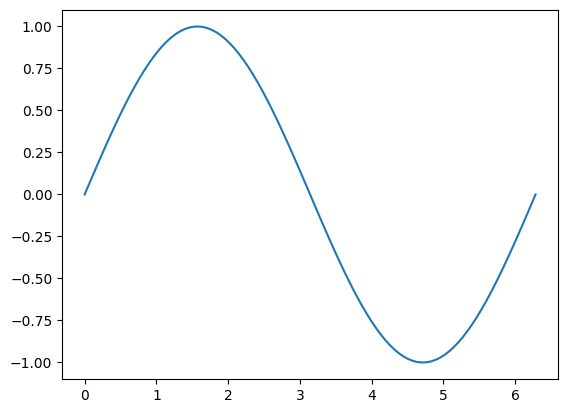

In [85]:
# TODO: xs = np.linspace(0, 2*np.pi, 100), plt.plot(xs, np.sin(xs)), plt.show()
xs = np.linspace(0, 2*np.pi, 100)
plt.plot(xs, np.sin(xs))
plt.show()


**Вправа 16.** На одному графіку познач дві групи точок різними кольорами і додай легенду.

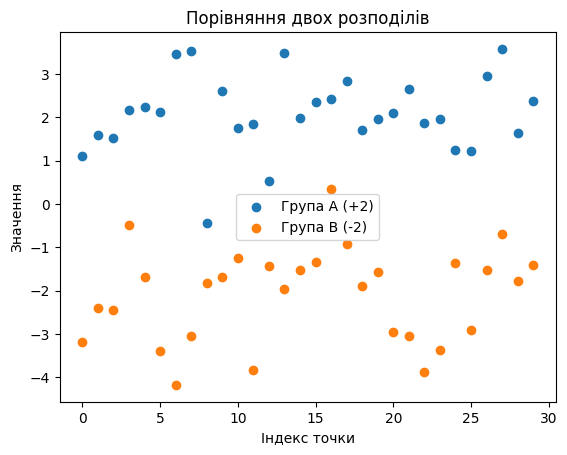

In [86]:
group_a = np.random.randn(30) + 2
group_b = np.random.randn(30) - 2

# TODO: scatter обох груп різними кольорами (color="C0"/"C1", label=...),
# додати plt.legend(), plt.show()

x_indices = np.arange(len(group_a))

plt.scatter(x_indices, group_a, color="C0", label="Група A (+2)")
plt.scatter(x_indices, group_b, color="C1", label="Група B (-2)")

plt.title("Порівняння двох розподілів")
plt.xlabel("Індекс точки")
plt.ylabel("Значення")
plt.legend()

plt.show()


---
## Завдання 1. Лінійна регресія

Тренуємо базовий пайплайн на простій лінійній регресії з одним параметром.

$$y = w \cdot x + b + \varepsilon, \quad \varepsilon \sim \mathcal{N}(0, 1)$$

In [87]:
TASK1_TRUE_W = 2.0
TASK1_TRUE_B = 1.0
TASK1_N = 300

x1 = torch.empty(TASK1_N, 1).uniform_(-5, 5)
noise = 1.0 * torch.randn(TASK1_N, 1)
y1 = TASK1_TRUE_W * x1 + TASK1_TRUE_B + noise

**Вправа 17.** Перш ніж будувати модель — подивись на самі дані.

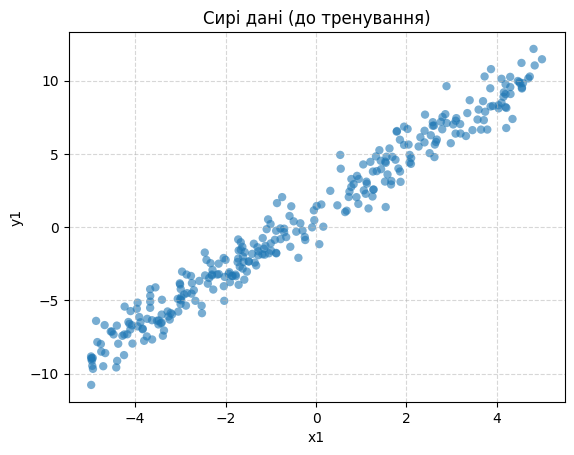

In [88]:
# TODO: Точкова діаграма (scatter plot) з вісями x1 та y1, підпис осей (xlabel/ylabel), заголовок
# "Сирі дані (до тренування)"
plt.scatter(x1.numpy(), y1.numpy(), alpha=0.6, color="C0", edgecolors="none")

# Підписи та оформлення
plt.xlabel("x1")
plt.ylabel("y1")
plt.title("Сирі дані (до тренування)")
plt.grid(True, linestyle="--", alpha=0.5)

plt.show()

**Вправа 18.** Розбий дані на train/val/test (70/15/15). Перемішай дані перед зрізом, інакше спліт вийде не випадковим.

In [89]:
# TODO: перемішати x1/y1 через torch.randperm(TASK1_N), розбити на
# train/val/test у пропорції 70/15/15
# x_train1, y_train1 = ...
# x_val1, y_val1 = ...
# x_test1, y_test1 = ...

n_train = int(0.70 * TASK1_N)
n_val = int(0.15 * TASK1_N)
n_test = TASK1_N - n_train - n_val

# Генеруємо єдиний вектор перестановки індексів
indices = torch.randperm(TASK1_N)

# Застосовуємо однакові індекси до x1 та y1, щоб зберегти відповідність пар
x_shuffled = x1[indices]
y_shuffled = y1[indices]

# Зрізи для кожної вибірки
x_train1, y_train1 = x_shuffled[:n_train], y_shuffled[:n_train]
x_val1, y_val1 = (
    x_shuffled[n_train : n_train + n_val],
    y_shuffled[n_train : n_train + n_val],
)
x_test1, y_test1 = (
    x_shuffled[n_train + n_val :],
    y_shuffled[n_train + n_val :],
)

print(f"train/val/test: {len(x_train1)}/{len(x_val1)}/{len(x_test1)}")


train/val/test: 210/45/45


**Вправа 19.** Нижче — готовий цикл навчання, кожен крок підписаний окремо. Просто запусти обидві комірки й подивись, як модель наближається до `true` за 100 епох (знімки кожні 30 епох).

In [90]:
task1_model = torch.nn.Linear(in_features=1, out_features=1)
optimizer = torch.optim.SGD(task1_model.parameters(), lr=0.05)
loss_fn = torch.nn.MSELoss()

x_line = torch.linspace(-5, 5, 100).unsqueeze(1)  # сітка для візуалізації лінії
snapshots = []  # (epoch, w, b, y_line_pred) кожні 30 епох

for epoch in range(100):
    # обнулити градієнти з попереднього кроку
    optimizer.zero_grad()
    # forward -- прогноз моделі на поточних w, b
    y_pred = task1_model(x_train1)
    # loss -- наскільки прогноз відрізняється від y_train1
    loss = loss_fn(y_pred, y_train1)
    # backward -- градієнти loss за w і b
    loss.backward()
    # крок оптимізатора -- оновити w і b
    optimizer.step()

    if epoch % 30 == 0 or epoch == 99:
        with torch.no_grad():
            y_line_pred = task1_model(x_line)
        snapshots.append((epoch, task1_model.weight.item(), task1_model.bias.item(), y_line_pred))
        print(f"epoch {epoch:4d}  loss={loss.item():.6f}  "
              f"w={task1_model.weight.item():.4f} (true {TASK1_TRUE_W})  "
              f"b={task1_model.bias.item():.4f} (true {TASK1_TRUE_B})")


epoch    0  loss=10.796704  w=1.7971 (true 2.0)  b=-0.2009 (true 1.0)
epoch   30  loss=1.030498  w=1.9806 (true 2.0)  b=1.0221 (true 1.0)
epoch   60  loss=1.026565  w=1.9829 (true 2.0)  b=1.0764 (true 1.0)
epoch   90  loss=1.026557  w=1.9830 (true 2.0)  b=1.0788 (true 1.0)
epoch   99  loss=1.026557  w=1.9830 (true 2.0)  b=1.0789 (true 1.0)


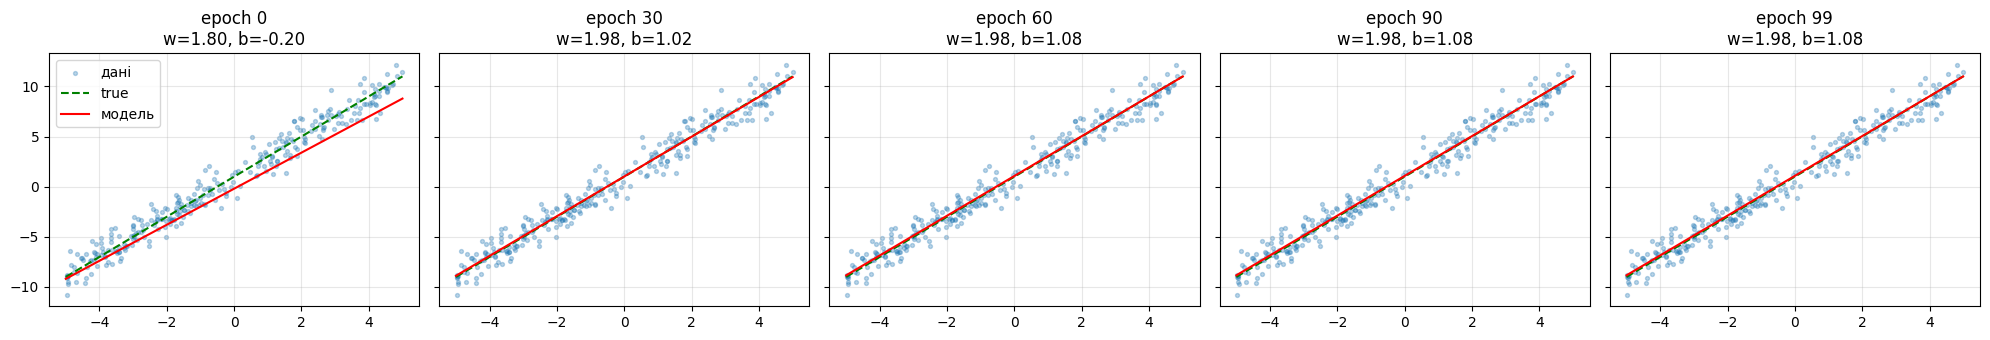

In [91]:
with torch.no_grad():
    y_line_true = TASK1_TRUE_W * x_line + TASK1_TRUE_B

fig, axes = plt.subplots(1, len(snapshots), figsize=(4 * len(snapshots), 3.5), sharey=True)
for ax, (epoch, w, b, y_line_pred) in zip(axes, snapshots):
    ax.scatter(x1.numpy(), y1.numpy(), s=8, alpha=0.3, label="дані")
    ax.plot(x_line.numpy(), y_line_true.numpy(), "g--", label="true")
    ax.plot(x_line.numpy(), y_line_pred.numpy(), "r-", label="модель")
    ax.set_title(f"epoch {epoch}\nw={w:.2f}, b={b:.2f}")
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()


**Вправа 20.** Придумай власний напів-реальний сценарій лінійної залежності
(наприклад: кількість з'їдених пачок чіпсів на тиждень → індекс маси тіла;
години сну → продуктивність; щось своє). У markdown-комірці перед кодом
опиши сценарій: яку залежність ти
закладаєш ($w$, $b$) і чому саме такі значення видались тобі правдоподібними.
Згенеруй дані з шумом, збережи їх у CSV файл (за зразком відповідної частини лекції)
і натренуй лінійну регресію за тим самим патерном — спліт, цикл навчання, перевірка на test.
Організуй код тренування у логічні перевикористовувані функції.

#### Залежність часу доставки піци від відстані до замовника

**Ознака ($x$):** Відстань від піцерії до адреси клієнта (в кілометрах, від 1 до 18 км).  
**Цільова змінна ($y$):** Загальний час виконання замовлення (у хвилинах).

**Обґрунтування параметрів:**
* **$w = 3.2$ хв/км (вага):** Середня швидкість кур'єра на скутері чи авто в умовах міського руху (світлофори, пішохідні переходи, пошук паркомісця) становить приблизно 18–20 км/год. Це дає близько 3–3.5 хвилин на подолання кожного кілометра шляху.
* **$b = 18.0$ хв (зсув / bias):** Базовий фіксований час, не залежний від відстані. Сюди входять: розкатка тіста, випікання в печі (~10–12 хв), упаковка в термосумку та спуск кур'єра з піцерії.
* **Шум $\epsilon \sim \mathcal{N}(0, 4^2)$:** Випадкові затримки на світлофорах, очікування ліфта в будинку замовника, черга на кухні в пікові години.

Формула моделі:  
$$y = 3.2 \cdot x + 18.0 + \epsilon$$

In [92]:
import torch.nn as nn
torch.manual_seed(42)

N_ORDERS = 400
TRUE_W = 3.2
TRUE_B = 18.0
NOISE_STD = 4.0

# Відстані від 1.0 до 18.0 км
distances = torch.empty(N_ORDERS, 1).uniform_(1.0, 18.0)
noise = NOISE_STD * torch.randn(N_ORDERS, 1)
delivery_times = TRUE_W * distances + TRUE_B + noise

# Збереження у CSV
df_pizza = pd.DataFrame(
    {
        "distance_km": distances.squeeze().numpy(),
        "delivery_time_min": delivery_times.squeeze().numpy(),
    }
)
csv_filename = "pizza_delivery_data.csv"
df_pizza.to_csv(csv_filename, index=False)
print(f"Збережено {len(df_pizza)} записів у файл '{csv_filename}'.\n")

Збережено 400 записів у файл 'pizza_delivery_data.csv'.



In [93]:
def prepare_data(x, y, train_ratio=0.70, val_ratio=0.15):
    """Перемішує та розбиває тензори на train / val / test."""
    total_n = x.shape[0]
    n_train = int(train_ratio * total_n)
    n_val = int(val_ratio * total_n)

    indices = torch.randperm(total_n)
    x_sh = x[indices]
    y_sh = y[indices]

    return {
        "x_train": x_sh[:n_train],
        "y_train": y_sh[:n_train],
        "x_val": x_sh[n_train : n_train + n_val],
        "y_val": y_sh[n_train : n_train + n_val],
        "x_test": x_sh[n_train + n_val :],
        "y_test": y_sh[n_train + n_val :],
    }


def train_linear_model(
    x_train, y_train, x_val, y_val, lr=0.001, epochs=300, print_every=50
):
    """Навчає лінійну регресію через SGD з валідацією."""
    model = nn.Linear(in_features=1, out_features=1)
    criterion = nn.MSELoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)

    for epoch in range(1, epochs + 1):
        model.train()
        optimizer.zero_grad()

        preds = model(x_train)
        loss = criterion(preds, y_train)
        loss.backward()
        optimizer.step()

        if epoch % print_every == 0 or epoch == 1:
            model.eval()
            with torch.no_grad():
                val_loss = criterion(model(x_val), y_val).item()
            print(
                f"Epoch {epoch:3d}/{epochs} | Train MSE: {loss.item():.2f} | Val MSE: {val_loss:.2f}"
            )

    return model


def evaluate_model(model, x_test, y_test, true_w, true_b):
    """Рахує фінальні метрики (MSE, MAE) на test та показує знайдені ваги."""
    model.eval()
    mse_crit = nn.MSELoss()
    mae_crit = nn.L1Loss()

    with torch.no_grad():
        preds = model(x_test)
        test_mse = mse_crit(preds, y_test).item()
        test_mae = mae_crit(preds, y_test).item()

    learned_w = model.weight.item()
    learned_b = model.bias.item()

    print("\n--- Результати на тестовій вибірці ---")
    print(f"Test MSE: {test_mse:.2f}")
    print(f"Test MAE: {test_mae:.2f} хв (середня похибка)")
    print(f"Справжні параметри:  w = {true_w:.2f}, b = {true_b:.2f}")
    print(f"Знайдені моделлю:    w = {learned_w:.2f}, b = {learned_b:.2f}")

In [94]:
# Завантаження з CSV
df_loaded = pd.read_csv(csv_filename)
x_raw = torch.tensor(df_loaded[["distance_km"]].values, dtype=torch.float32)
y_raw = torch.tensor(
    df_loaded[["delivery_time_min"]].values, dtype=torch.float32
)

# Розбиття на вибірки (70 / 15 / 15)
data = prepare_data(x_raw, y_raw, train_ratio=0.70, val_ratio=0.15)

# Тренування моделі
model = train_linear_model(
    data["x_train"],
    data["y_train"],
    data["x_val"],
    data["y_val"],
    lr=0.005,
    epochs=400,
    print_every=100,
)

# Тестування
evaluate_model(model, data["x_test"], data["y_test"], TRUE_W, TRUE_B)

Epoch   1/400 | Train MSE: 2786.70 | Val MSE: 98.05
Epoch 100/400 | Train MSE: 67.79 | Val MSE: 55.88
Epoch 200/400 | Train MSE: 49.02 | Val MSE: 39.30
Epoch 300/400 | Train MSE: 37.18 | Val MSE: 29.06
Epoch 400/400 | Train MSE: 29.70 | Val MSE: 22.77

--- Результати на тестовій вибірці ---
Test MSE: 33.70
Test MAE: 4.65 хв (середня похибка)
Справжні параметри:  w = 3.20, b = 18.00
Знайдені моделлю:    w = 3.76, b = 11.11


**Вправа 21.** Збережи натреновану модель на своєму гугл диску у файлі з назвою `model.pt`.
Збережений файл потрібно буде також здати разом з лабою.

In [95]:
model_save_path = "/content/drive/MyDrive/ai_systems/lab1/model.pt"
csv_save_path = "/content/drive/MyDrive/ai_systems/lab1/dataset.csv"
df_pizza.to_csv(csv_save_path, index=False)
torch.save(model.state_dict(), model_save_path)

**Вправа 22.** Встанови [Gradio](https://gradio.app/)
```
!pip install -q gradio
import gradio as gr
```
Завантаж свою модель, збережену в попередній вправі і створи інтерактивну аппку.

In [96]:
!pip install -q gradio
import gradio as gr

In [97]:
MODEL_PATH = "/content/drive/MyDrive/ai_systems/lab1/model.pt"
model = nn.Linear(in_features=1, out_features=1)
model.load_state_dict(torch.load(MODEL_PATH, weights_only=True))
model.eval()

# Функція для передбачення
def predict_delivery_time(distance_km: float) -> str:
    if distance_km <= 0:
        return "Введіть коректну відстань (> 0 км)"

    # Перетворюємо вхідне число у тензор форми [1, 1]
    input_tensor = torch.tensor([[distance_km]], dtype=torch.float32)

    with torch.no_grad():
        predicted_time = model(input_tensor).item()

    # Округлюємо до цілих або одного знака після коми
    return f"{predicted_time:.1f} хв"


# Створення UI за допомогою Gradio
demo = gr.Interface(
    fn=predict_delivery_time,
    inputs=gr.Slider(
        minimum=0.5,
        maximum=25.0,
        value=5.0,
        step=0.5,
        label="Відстань до замовника (км)",
    ),
    outputs=gr.Textbox(label="Очікуваний час доставки"),
    title="Калькулятор часу доставки піци",
    description="Інтерактивний прогноз на основі натренованої лінійної регресії",
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://02d0d9b2a513e1831a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу
У [форму](https://forms.gle/5qxRYshxKknBXDCz8) здати посилання на **публічний** репозиторій, який містить:
1. **Цей ноутбук з усіма виконаними вправами**. Ноутбук має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Додаткові скріншоти** по ходу виконання лаби (якими Ви доводите, що справді виконували цбю лабу).
3. Створений по ходу виконання лаби **csv файл** з даними і **pt файл** з моделлю.
4. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
    /lab1/linear_models_lab.ipynb
    /lab1/screenshots/*
    /lab1/dataset.csv
    /lab1/model.pt
```